# Projeto de Classificação de Imagens Oftalmológicas com Deep Learning



## 01 - EDA e preaparação de dados

#  Introdução e contexto
---

**Contextualização do Caso Clínico: Sistema de Referenciação Hospitalar**
O objetivo principal deste projeto é desenvolver e avaliar um sistema de apoio à decisão clínica baseado em Deep Learning para a classificação de imagens oftalmológicas (Catarata, Retinopatia Diabética e Normal).

No âmbito de uso, o sistema atua como um filtro crítico no fluxo de triagem hospitalar. 
O foco principal não é apenas maximizar a exatidão global (*accuracy*), mas sim reduzir o volume de exames enviados desnecessariamente para avaliação especializada, garantindo em simultâneo uma sensibilidade (*recall*) extremamente elevada nas classes patológicas para evitar a ocorrência de Falsos Negativos (doentes com patologia que não são referenciados).

## 1 — Carregamento, Configuração, reproducibilidade e EDA 
---

Nesta secção, configuramos o ambiente de desenvolvimento, definimos a reproducibilidade do sistema e analisamos as características estruturais e estatísticas do dataset fornecido.

Aqui são utilizadas funções importadas do modulo /src ao longo do notebook

In [7]:
# Importações necessárias

import os, random, hashlib
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


In [8]:
# Definir seed para garantir que os resultados sejam consistentes entre execuções.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)


In [ ]:
# Projeto foi desenvolvido no Google Colab, mas também pode ser executado localmente.
# O código abaixo garante que o caminho do repositório seja adicionado ao sys.path, 
# independentemente do ambiente em que o código está sendo executado.
try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount('/content/drive')
    import sys
    sys.path.insert(0, '/content/drive/MyDrive/ophthalmic-referral-cnn')
except ImportError:
    import os, sys
    sys.path.insert(0, os.getcwd())

from src import bootstrap, data, viz

IN_COLAB = bootstrap.setup()
REPO_DIR = bootstrap.get_repo_dir(IN_COLAB)
DATA_DIR = bootstrap.get_data_dir(IN_COLAB, REPO_DIR)
base_dir = str(DATA_DIR)

# carregamento do dataset
X_original, y, nomes_ficheiros, labels_ficheiros, folders = data.load_dataset(DATA_DIR)

cataract_folder = folders[0][1]
diabetic_folder = folders[1][1]
normal_folder = folders[2][1]

print(cataract_folder)
print(diabetic_folder)
print(normal_folder)

# Verificar o formato dos dados
print(f"Formato dos dados: {X_original.shape}")
print(f"Formato das labels: {y.shape}")

ModuleNotFoundError: No module named 'src'

In [ ]:
# Diretórios de artefactos -- sempre em Drive (ARTIFACTS_DIR deriva de
# REPO_DIR, que já aponta para o Drive em Colab), nunca em /content/, que
# desaparece se a sessão do Colab terminar.
ARTIFACT_DIRS = bootstrap.get_artifact_dirs(REPO_DIR)
ARTIFACTS_DIR = ARTIFACT_DIRS["artifacts"]
MODELS_DIR    = ARTIFACT_DIRS["models"]
PREDS_DIR     = ARTIFACT_DIRS["preds"]
HISTORY_DIR   = ARTIFACT_DIRS["history"]
for _d in (MODELS_DIR, PREDS_DIR, HISTORY_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Artefactos em:", ARTIFACTS_DIR)

In [ ]:
# Mapa de pastas -> nome legível (alinhado com os labels 0/1/2)
FOLDERS = {
    0: ("cataract", cataract_folder),
    1: ("diabetic_retinopathy", diabetic_folder),
    2: ("normal", normal_folder),
}

print("="*60)
print("INVENTÁRIO E INTEGRIDADE")
print("="*60)

records = []          # (classe, ficheiro, ok, largura, altura, modo, hash)
corrupt = []
for lab, (name, folder) in FOLDERS.items():
    for fn in sorted(os.listdir(folder)):
        path = os.path.join(folder, fn)
        try:
            with Image.open(path) as im:     # deteta corrupção
                im.verify()
            with Image.open(path) as im:     # reabrir: verify() invalida o objeto
                w, h = im.size
                mode = im.mode
            with open(path, "rb") as f:
                h_md5 = hashlib.md5(f.read()).hexdigest()
            records.append((lab, name, fn, w, h, mode, h_md5))
        except Exception as e:
            corrupt.append((name, fn, str(e)))

print(f"Total de ficheiros válidos: {len(records)}")
print(f"Ficheiros corrompidos / não abrem: {len(corrupt)}")
for c in corrupt[:10]:
    print("   ", c)

# --- Dimensões originais  ---
print("\n" + "="*60)
print("DIMENSÕES ORIGINAIS")
print("="*60)
dims = Counter((r[3], r[4]) for r in records)
print("Tamanhos mais comuns (largura, altura):")
for (w, h), n in dims.most_common(8):
    print(f"   {w}x{h}: {n} imagens")
modes = Counter(r[5] for r in records)
print("Modos de cor:", dict(modes))

# --- Duplicados por conteúdo (hash) ---
print("\n" + "="*60)
print("DUPLICADOS")
print("="*60)
by_hash = defaultdict(list)
for r in records:
    by_hash[r[6]].append((r[1], r[2]))   # (classe, ficheiro)
dups = {h: v for h, v in by_hash.items() if len(v) > 1}
print(f"Grupos de imagens idênticas: {len(dups)}")
total_dup_imgs = sum(len(v) for v in dups.values())
print(f"Total de imagens envolvidas: {total_dup_imgs}")

cross_class = 0
for h, v in dups.items():
    classes = set(c for c, _ in v)
    if len(classes) > 1:
        cross_class += 1
print(f"Grupos que CRUZAM classes diferentes: {cross_class}")
if cross_class > 0:
    print("  -> mesma imagem com labels diferentes: erro de dataset")



INVENTÁRIO E INTEGRIDADE
Total de ficheiros válidos: 2570
Ficheiros corrompidos / não abrem: 0

DIMENSÕES ORIGINAIS
Tamanhos mais comuns (largura, altura):
   512x512: 2470 imagens
   2592x1728: 76 imagens
   2464x1632: 19 imagens
   1848x1224: 5 imagens
Modos de cor: {'RGB': 2570}

DUPLICADOS
Grupos de imagens idênticas: 0
Total de imagens envolvidas: 0
Grupos que CRUZAM classes diferentes: 0


In [ ]:
# Verifica quantas imagens estão fora da norma 512X512 e a sua classe
big = [r for r in records if (r[3], r[4]) != (512, 512)]
print("Imagens não-512x512 por classe:")
print(Counter(r[1] for r in big))   # r[1] = nome da classe

Imagens não-512x512 por classe:
Counter({'cataract': 100})


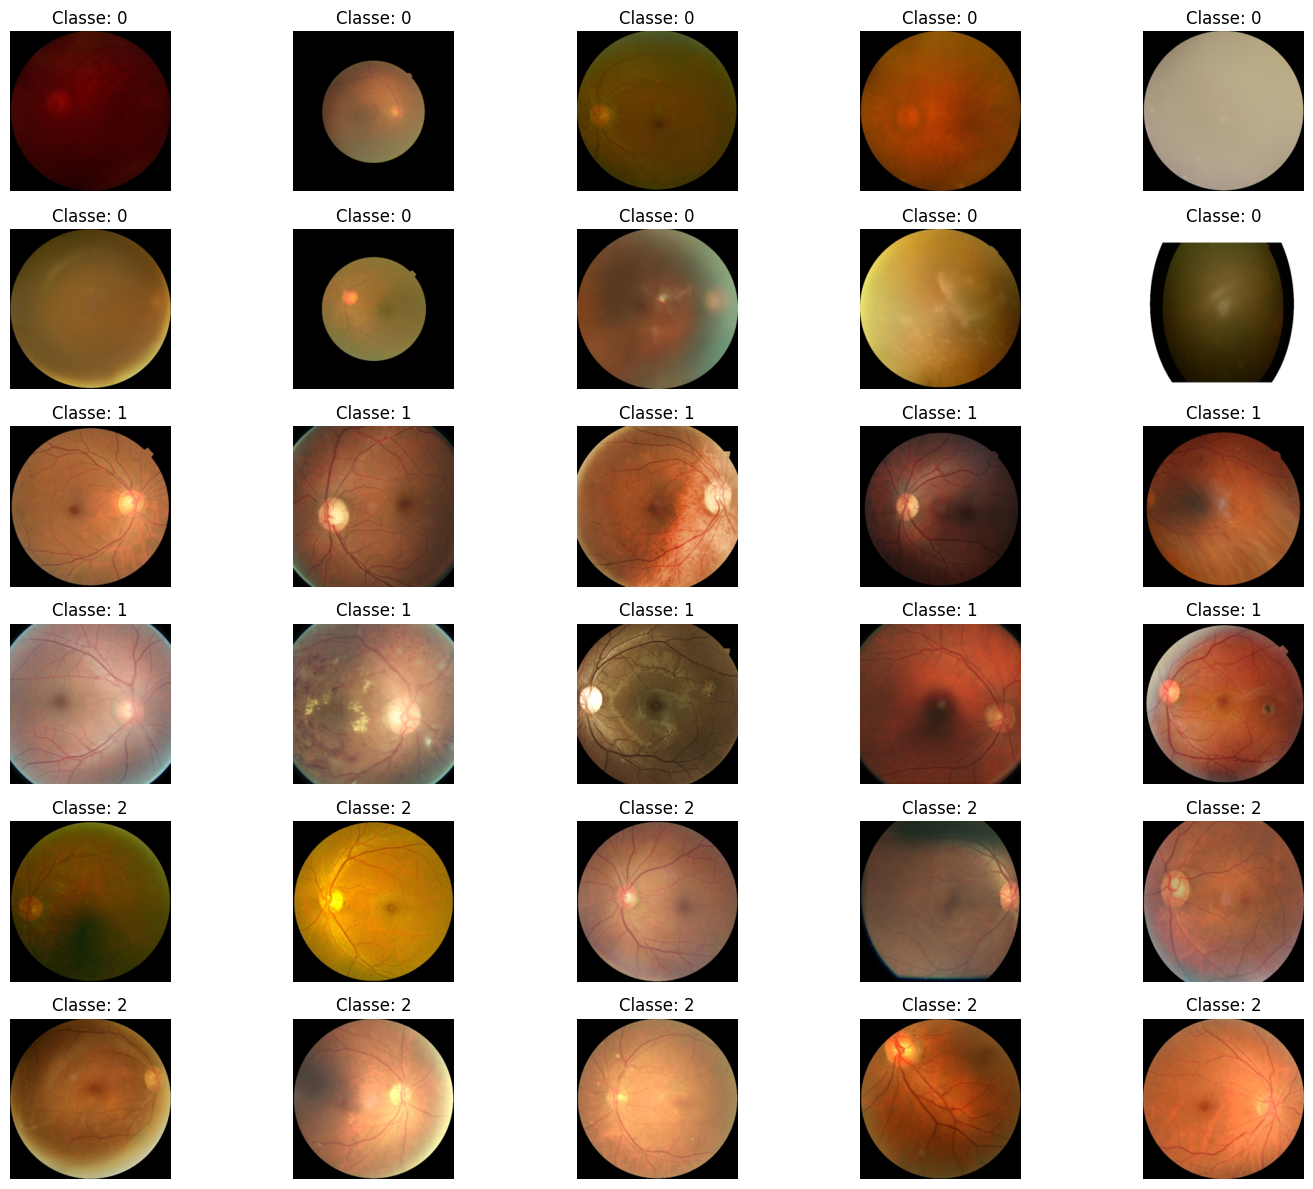

In [7]:
# Índices das imagens de cada classe
idx_classe_0 = np.where(y == 0)[0]
idx_classe_1 = np.where(y == 1)[0]
idx_classe_2 = np.where(y == 2)[0]

# Amostra aleatória de 10 imagens por classe
amostra_0 = np.random.choice(idx_classe_0, size=10, replace=False)
amostra_1 = np.random.choice(idx_classe_1, size=10, replace=False)
amostra_2 = np.random.choice(idx_classe_2, size=10, replace=False)

# Juntar todas as amostras
amostras = np.concatenate([amostra_0, amostra_1, amostra_2])

# Visualizar 30 imagens: 10 da classe 0, 10 da classe 1 e 10 da classe 2
plt.figure(figsize=(15, 12))

for i, idx in enumerate(amostras):
    plt.subplot(6, 5, i + 1)  # 6 linhas x 5 colunas = 30 imagens
    plt.imshow(X_original[idx])
    plt.title(f"Classe: {y[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

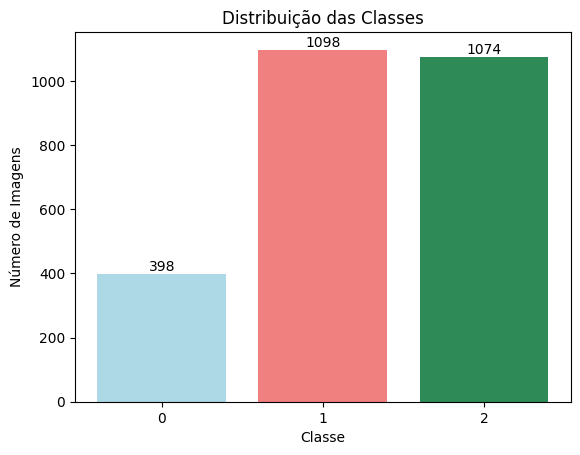

In [8]:
# gráfico de barras para visualizar a distribuição das classes
classes, counts = np.unique(y, return_counts=True)
plt.bar(classes, counts, color=['lightblue', 'lightcoral', 'seagreen'])
plt.xlabel('Classe')
plt.ylabel('Número de Imagens')
plt.title('Distribuição das Classes')
plt.xticks(classes)
for i, (class_label, count) in enumerate(zip(classes, counts)):
    plt.text(i, count + 0.5, str(count), ha='center', va='bottom')
plt.show()

In [9]:
print("Shape de X:", X_original.shape)
print("Shape de y:", y.shape)
print("Classes únicas em y:", np.unique(y))

Shape de X: (2570, 224, 224, 3)
Shape de y: (2570,)
Classes únicas em y: [0 1 2]


Total de imagens: 2570
Total de pacientes únicos: 1454

Distribuição (nº de imagens -> nº de pacientes):
   1 imagem(ns): 346 pacientes
   2 imagem(ns): 1102 pacientes
   3 imagem(ns): 4 pacientes
   4 imagem(ns): 2 pacientes

Pacientes com >1 imagem: 1108
   dos quais com classes DIFERENTES entre olhos: 6


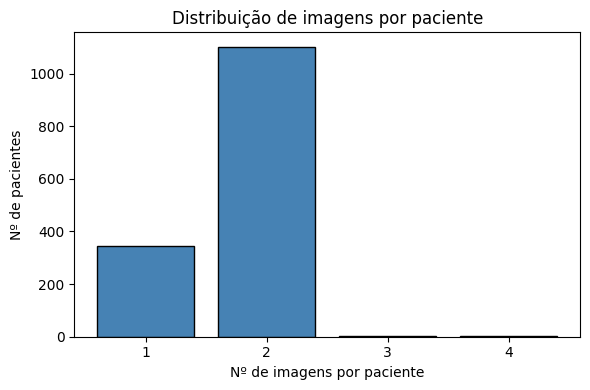

In [10]:
# EDA: análise ao nível do PACIENTE
# As imagens seguem o padrão {id}_{left/right}.jpg, sugerindo
# pares de olhos do mesmo paciente. Verificamos a estrutura.
# id_paciente() vem de src/data.py (estava duplicada aqui e na célula do split).

classes_por_ficheiro = [folders[l][0] for l in labels_ficheiros]
todos = [(data.id_paciente(f), c) for f, c in zip(nomes_ficheiros, classes_por_ficheiro)]

# nº de imagens por paciente
imgs_por_paciente = Counter(p for p, _ in todos)
dist = Counter(imgs_por_paciente.values())

print(f"Total de imagens: {len(todos)}")
print(f"Total de pacientes únicos: {len(imgs_por_paciente)}")
print(f"\nDistribuição (nº de imagens -> nº de pacientes):")
for n_imgs in sorted(dist):
    print(f"   {n_imgs} imagem(ns): {dist[n_imgs]} pacientes")

# verificar se os olhos do mesmo paciente partilham classe
classes_por_paciente = defaultdict(set)
for p, c in todos:
    classes_por_paciente[p].add(c)

multi = [p for p, cs in classes_por_paciente.items()
         if imgs_por_paciente[p] > 1]
discordantes = [p for p in multi if len(classes_por_paciente[p]) > 1]
print(f"\nPacientes com >1 imagem: {len(multi)}")
print(f"   dos quais com classes DIFERENTES entre olhos: {len(discordantes)}")

# gráfico da distribuição
plt.figure(figsize=(6, 4))
plt.bar([str(k) for k in sorted(dist)], [dist[k] for k in sorted(dist)],
        color="steelblue", edgecolor="black")
plt.title("Distribuição de imagens por paciente")
plt.xlabel("Nº de imagens por paciente")
plt.ylabel("Nº de pacientes")
plt.tight_layout()
plt.show()

## 1.1— Preparação dos dados
---
Normalização das imagens
Codificação das labels
Divisão treino, validação e teste

Nesta fase foi realizada a preparação dos dados para treino dos modelos de Deep Learning.

As imagens foram normalizadas para o intervalo [0,1], permitindo uma aprendizagem mais estável e eficiente da rede neuronal.

Posteriormente, os dados foram divididos em conjuntos de treino, validação e teste. 
Esta divisão permite avaliar corretamente a capacidade de generalização do modelo em dados nunca observados durante o treino.

Por fim, foi feito one-hot encoding para, adequado para problemas de classificação multiclasse.

In [11]:
# Normalização das imagens

X = X_original.astype("float32") / 255.0

print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())

Valor mínimo: 0.0
Valor máximo: 1.0


In [12]:
# Conversão dos labels para inteiro

y = y.astype(int)

In [13]:
# As labels já se encontram codificadas (0, 1 e 2)

class_names = ["Cataract", "Diabetic Retinopathy", "Normal"]

y_encoded = y.copy()

print("Classes:", class_names)
print("Labels únicas:", np.unique(y_encoded))

Classes: ['Cataract', 'Diabetic Retinopathy', 'Normal']
Labels únicas: [0 1 2]


## 1.2 Pré-processamento e Divisão dos Dados

Os dados são divididos em três conjuntos independentes:
- **Treino** — para o ajuste dos pesos do modelo;
- **Validação** — para monitorização do treino, *early stopping* e seleção de
  hiperparâmetros;
- **Teste** — para a avaliação final, intocado durante o treino, simulando o
  desempenho do sistema perante novos exames.

A divisão é feita ao nível do **paciente**, e não da imagem. Como o conjunto contém
pares de olhos do mesmo paciente (esquerdo e direito), um split aleatório por imagem
colocaria, com elevada probabilidade, os dois olhos de um indivíduo em conjuntos
diferentes. Dada a semelhança visual entre olhos do mesmo paciente, isso introduziria
*data leakage* e anflacionaria artificialmente as métricas de teste.

Para o evitar, utilizámos um *split* **estratificado por grupos**
(`StratifiedGroupKFold`), garantindo simultaneamente que:
*(i)* todas as imagens de um
paciente permanecem no mesmo conjunto e 
*(ii)* as proporções das três classes são
preservadas em cada conjunto. A divisão resultante (~60% treino, ~20% validação,
~20% teste) mantém as 2570 imagens, sem exclusão de dados.

In [ ]:
# SPLIT POR PACIENTE (evita leakage de olhos emparelhados)
# id_paciente() e a lógica de split vêm de src/data.py 

groups = data.build_groups(nomes_ficheiros)

# Alignment check. Compara a classe implícita pela pasta de origem de cada
# ficheiro com y, elemento a elemento, para apanhar imediatamente um
# reordenamento (comparar só o comprimento não apanharia isso).
assert len(groups) == len(X_original), \
    f"groups ({len(groups)}) != X_original ({len(X_original)})"
assert np.array_equal(labels_ficheiros, y), \
    "ordem dos ficheiros desalinhada com y — groups/X_original não correspondem!"
assert len(nomes_ficheiros) == len(X_original), \
    "nomes_ficheiros e X_original têm comprimentos diferentes!"

split = data.split_patient_grouped(X_original, y, groups, seed=SEED)
trainval_idx, test_idx = split["trainval_idx"], split["test_idx"]
train_idx, val_idx = split["train_idx"], split["val_idx"]

X_trainval, X_test = X_original[trainval_idx], X_original[test_idx]
y_trainval, y_test = y[trainval_idx], y[test_idx]
groups_trainval = groups[trainval_idx]

X_train, X_val = X_original[train_idx], X_original[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

In [15]:
# verificação se split foi bem sucedido

g_train = set(groups[train_idx])
g_val   = set(groups[val_idx])
g_test  = set(groups[test_idx])

print("Pacientes -> treino:", len(g_train), "| val:", len(g_val), "| teste:", len(g_test))
print("Sobreposição treino/teste:", len(g_train & g_test))
print("Sobreposição treino/val:  ", len(g_train & g_val))
print("Sobreposição val/teste:   ", len(g_val & g_test))

print("\nImagens -> treino:", len(X_train), "| val:", len(X_val), "| teste:", len(X_test))
print("Classes treino:", np.bincount(y_train))
print("Classes val:   ", np.bincount(y_val))
print("Classes teste: ", np.bincount(y_test))

Pacientes -> treino: 873 | val: 292 | teste: 289
Sobreposição treino/teste: 0
Sobreposição treino/val:   0
Sobreposição val/teste:    0

Imagens -> treino: 1541 | val: 522 | teste: 507
Classes treino: [241 654 646]
Classes val:    [ 75 226 221]
Classes teste:  [ 82 218 207]


In [ ]:
# Persistir os índices do split e os labels de teste/treino -- os artefactos
# que permitem a qualquer notebook (ou sessão) reconstruir os mesmos
# conjuntos sem GPU nem re-treino.
data.save_split_indices(ARTIFACTS_DIR / "split_indices.npz", split)
np.save(PREDS_DIR / "y_test.npy", y_test)
np.save(PREDS_DIR / "y_train.npy", y_train)
print("Guardado:", ARTIFACTS_DIR / "split_indices.npz")
print("Guardado:", PREDS_DIR / "y_test.npy")
print("Guardado:", PREDS_DIR / "y_train.npy")

In [16]:
# Verificação da escala dos pixels (antes de treinar)
print("Intervalo de valores dos pixels")
print(f"  treino     -> min: {X_train.min():.4f}   max: {X_train.max():.4f}")
print(f"  validação  -> min: {X_val.min():.4f}   max: {X_val.max():.4f}")
print(f"  teste      -> min: {X_test.min():.4f}   max: {X_test.max():.4f}")
print(f"Formato dos dados (X): {X.shape}")
print(f"  dtype: {X_train.dtype}")


Intervalo de valores dos pixels
  treino     -> min: 0.0000   max: 255.0000
  validação  -> min: 0.0000   max: 255.0000
  teste      -> min: 0.0000   max: 255.0000
Formato dos dados (X): (2570, 224, 224, 3)
  dtype: uint8


In [17]:
# verificação de exemplo de array de pixeis de imagem do dataset
print(X_train[1])

[[[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 ...

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]]
